## Import

In [1]:
import kagglehub
from pathlib import Path

data_dir = Path("./Data")

if not data_dir.exists() or not any(data_dir.iterdir()):
    path = Path(kagglehub.dataset_download("kmader/finding-lungs-in-ct-data"))
    print("Dataset downloaded to:", path)
else:
    path = data_dir
    print("Dataset already exists at:", path.resolve())

Dataset downloaded to: /iahome/j/jk/jkitzmann/.cache/kagglehub/datasets/kmader/finding-lungs-in-ct-data/versions/2


In [2]:
import SimpleITK as sitk
import numpy as np
import matplotlib.pyplot as plt
import os
import torch
from torch.utils.data import Dataset, DataLoader
import torchvision
from sklearn.model_selection import train_test_split
import torch.nn as nn
import torch.nn.functional as F
import copy

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)

device = 'cuda'

PyTorch: 2.8.0+cu128
Torchvision: 0.23.0+cu128


## Helpful functions

In [3]:
def show_slice(image, segmentation=None, title=None):

    # Handle PyTorch tensors
    if isinstance(image, torch.Tensor):
        im = image.squeeze().detach().cpu().numpy()
        seg = segmentation.squeeze().detach().cpu().numpy() if segmentation is not None else None

    # Handle SimpleITK images
    else:
        im = sitk.GetArrayFromImage(image)
        seg = sitk.GetArrayFromImage(segmentation) if segmentation is not None else None


    plt.figure(figsize=(7, 7))
    plt.imshow(im, cmap="gray")
    plt.colorbar()
    if title != None:
        plt.title(title)


    if seg is not None:
        plt.imshow(
            np.ma.masked_where(seg == 0, seg),
            cmap="autumn",
            alpha=0.5
        )

    plt.axis("off")
    plt.show()


## Dataset

In [4]:
image_dir = Path(path) / "3d_images"

image_files = sorted(image_dir.glob("IMG_*.nii.gz"))
mask_files = sorted(image_dir.glob("MASK_*.nii.gz"))

In [5]:
images = {
    f.name.replace("IMG_", "").replace(".nii.gz", ""): f
    for f in image_files
}

masks = {
    f.name.replace("MASK_", "").replace(".nii.gz", ""): f
    for f in mask_files
}

assert images.keys() == masks.keys(), "ids don't match"

volume_pairs = [
    (images[volume_id], masks[volume_id])
    for volume_id in sorted(images)
]

print(f"Successfully paired {len(volume_pairs)} volumes.")

Successfully paired 4 volumes.


In [6]:
class LungDataset(Dataset):

    def __init__(self, volume_pairs):
        self.images = []
        self.masks = []
        self.slice_indices = []

        for image_file, mask_file in volume_pairs:

            image = sitk.ReadImage(str(image_file))
            mask = sitk.ReadImage(str(mask_file))

            # preprocessing
            image = sitk.Normalize(image)

            image = sitk.GetArrayFromImage(image).astype(np.float32)
            mask = sitk.GetArrayFromImage(mask).astype(np.int32)
            mask = (mask > 0).astype(np.uint8)

            self.images.append(image)
            self.masks.append(mask)

            volume_idx = len(self.images) - 1

            for z in range(image.shape[2]):
                self.slice_indices.append((volume_idx, z))

    def __len__(self):
        return len(self.slice_indices)

    def __getitem__(self, idx):

        volume_idx, slice_idx = self.slice_indices[idx]

        image = self.images[volume_idx][:, :, slice_idx]
        mask = self.masks[volume_idx][:, :, slice_idx]

        image = torch.from_numpy(image.copy()).float().unsqueeze(0)
        mask = torch.from_numpy(mask.copy()).long()

        return image, mask

Total slices: 1208
Image shape: torch.Size([1, 512, 512])
Mask shape: torch.Size([512, 512])


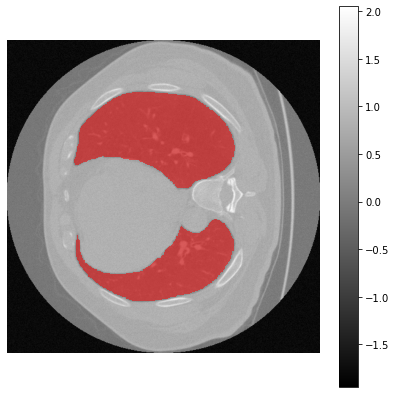

In [7]:
dataset = LungDataset(volume_pairs)

print("Total slices:", len(dataset))

image, mask = dataset[500]

print("Image shape:", image.shape)
print("Mask shape:", mask.shape)

show_slice(image, mask)

## Split

In [ ]:
train_pairs, val_pairs = train_test_split(
    volume_pairs,
    test_size=0.25,
    random_state=42
)

train_dataset = LungDataset(train_pairs)
val_dataset = LungDataset(val_pairs)

train_loader = DataLoader(
    train_dataset,
    batch_size=8,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=8,
    shuffle=False,
    num_workers=0
)

print("Training volumes:", len(train_pairs))
print("Validation volumes:", len(val_pairs))
print("Training slices:", len(train_dataset))
print("Validation slices:", len(val_dataset))

In [ ]:
show_slice(train_dataset[100][0], train_dataset[100][1], title='training data')
show_slice(val_dataset[100][0], val_dataset[100][1], title='validation data')

## U-Net

In [ ]:
class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.conv = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),

            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.conv(x)


In [ ]:

class UNet2D(nn.Module):
    def __init__(self, in_channels=1, num_classes=2, features=32):
        super().__init__()

        # encoder
        self.enc1 = DoubleConv(in_channels, features)
        self.enc2 = DoubleConv(features, features * 2)
        self.enc3 = DoubleConv(features * 2, features * 4)
        self.enc4 = DoubleConv(features * 4, features * 8)

        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)

        # bottleneck
        self.bottleneck = DoubleConv(features * 8, features * 16)

        # decoder
        self.up4 = nn.ConvTranspose2d(features * 16, features * 8, kernel_size=2, stride=2)
        self.dec4 = DoubleConv(features * 16, features * 8)

        self.up3 = nn.ConvTranspose2d(features * 8, features * 4, kernel_size=2, stride=2)
        self.dec3 = DoubleConv(features * 8, features * 4)

        self.up2 = nn.ConvTranspose2d(features * 4, features * 2, kernel_size=2, stride=2)
        self.dec2 = DoubleConv(features * 4, features * 2)

        self.up1 = nn.ConvTranspose2d(features * 2, features, kernel_size=2, stride=2)
        self.dec1 = DoubleConv(features * 2, features)

        # classification
        self.out = nn.Conv2d(features, num_classes, kernel_size=1)

    def forward(self, x):

        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))

        b = self.bottleneck(self.pool(e4))

        d4 = self.up4(b)
        d4 = F.interpolate(d4, size=e4.shape[2:], mode="bilinear", align_corners=False)
        d4 = self.dec4(torch.cat([d4, e4], dim=1))

        d3 = self.up3(d4)
        d3 = F.interpolate(d3, size=e3.shape[2:], mode="bilinear", align_corners=False)
        d3 = self.dec3(torch.cat([d3, e3], dim=1))

        d2 = self.up2(d3)
        d2 = F.interpolate(d2, size=e2.shape[2:], mode="bilinear", align_corners=False)
        d2 = self.dec2(torch.cat([d2, e2], dim=1))

        d1 = self.up1(d2)
        d1 = F.interpolate(d1, size=e1.shape[2:], mode="bilinear", align_corners=False)
        d1 = self.dec1(torch.cat([d1, e1], dim=1))

        return self.out(d1)


## Train

In [ ]:
def run_epoch(model, loader, criterion, device, optimizer=None):

    training = optimizer is not None

    if training:
        model.train()
    else:
        model.eval()

    total_loss = 0.0
    total_samples = 0

    # Accumulate foreground Dice statistics
    total_tp = 0
    total_fp = 0
    total_fn = 0

    for images, masks in loader:

        images = images.to(device)
        masks = masks.to(device)

        if training:
            optimizer.zero_grad()

        # Forward pass
        with torch.set_grad_enabled(training):
            outputs = model(images)
            loss = criterion(outputs, masks)

            if training:
                loss.backward()
                optimizer.step()

        # Accumulate loss
        batch_size = images.size(0)
        total_loss += loss.item() * batch_size
        total_samples += batch_size

        # Convert logits into predicted class labels
        predictions = outputs.argmax(dim=1)

        # Calculate foreground statistics
        total_tp += ((predictions == 1) & (masks == 1)).sum().item()
        total_fp += ((predictions == 1) & (masks == 0)).sum().item()
        total_fn += ((predictions == 0) & (masks == 1)).sum().item()

    # Epoch-level metrics
    epoch_loss = total_loss / total_samples

    dice = (2 * total_tp + 1e-8) / (
        2 * total_tp + total_fp + total_fn + 1e-8
    )

    return epoch_loss, dice


In [ ]:
model = UNet2D(
    in_channels=1,
    num_classes=2,
    features=32
).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)
criterion = nn.CrossEntropyLoss()

num_epochs = 30
best_val_dice = -1.0

history = {
    'train_loss': [],
    'val_loss': [],
    'train_dice': [],
    'val_dice': []
}

for epoch in range(num_epochs):

    train_loss, train_dice = run_epoch(
        model, train_loader, criterion, device, optimizer
    )

    val_loss, val_dice = run_epoch(
        model, val_loader, criterion, device
    )

    # Store metrics
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_dice"].append(train_dice)
    history["val_dice"].append(val_dice)

    # Save best model
    if val_dice > best_val_dice:
        best_val_dice = val_dice

        torch.save({
            "epoch": epoch + 1,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "val_dice": val_dice
        }, "best_unet2d.pth")

    print(
        f"Epoch [{epoch + 1:02d}/{num_epochs}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Train Dice: {train_dice:.4f} | "
        f"Val Dice: {val_dice:.4f}"
    )

print(f"\nBest validation Dice: {best_val_dice:.4f}")


In [ ]:

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Loss
axes[0].plot(history["train_loss"], label="Training")
axes[0].plot(history["val_loss"], label="Validation")
axes[0].set_title("Cross-Entropy Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()

# Dice
axes[1].plot(history["train_dice"], label="Training")
axes[1].plot(history["val_dice"], label="Validation")
axes[1].set_title("Foreground Dice")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Dice")
axes[1].legend()

plt.tight_layout()
plt.show()


# Apply to validation image

In [ ]:
checkpoint = torch.load(
    'best_unet2d.pth',
    map_location=device,
    weights_only=True
)

model.load_state_dict(checkpoint["model_state_dict"])
model.to(device)
model.eval()

In [ ]:
def predict_volume(model, image, device, batch_size=8):

    volume = sitk.GetArrayFromImage(image).astype(np.float32)
    prediction = np.zeros(volume.shape, dtype=np.uint16)

    model.eval()

    with torch.no_grad():

        for start in range(0, volume.shape[2], batch_size):

            end = min(start + batch_size, volume.shape[2])

            # Extract slices along axis 2
            slices = volume[:, :, start:end]
            slices = np.moveaxis(slices, 2, 0)

            # Normalize each slice
            mean = slices.mean(axis=(1, 2), keepdims=True)
            std = slices.std(axis=(1, 2), keepdims=True)
            slices = (slices - mean) / (std + 1e-8)

            inputs = torch.from_numpy(slices.copy()).float().unsqueeze(1).to(device)

            outputs = model(inputs)
            predictions = outputs.argmax(dim=1).cpu().numpy()

            prediction[:, :, start:end] = np.moveaxis(predictions, 0, 2)

    return prediction

In [ ]:
test_im = sitk.ReadImage(image_files[3])

prediction = predict_volume(
    model,
    test_im,
    device,
    batch_size=8
)

show_slice(test_im, sitk.GetImageFromArray(prediction))